In [1]:
import sghf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
model = sghf.load("/home/lorenz/work/reinterpretation/knunu-reinterpretation-mini/scripts/data/combined_likelihood.json")

In [3]:
fit = model.fit()

In [4]:
print(fit.value(model.poi_name), fit.error(model.poi_name))

4.124086289758145 1.1281623530955247


In [5]:
asymptotic = model.hypotest(
    0.5, 
    variance="nominal",
    test_stat="qtilde"
    )
print(asymptotic.cls, asymptotic.expected_cls)

0.7449466963857533 (0.3199480970893072, 0.46945980039148355, 0.657622075711343, 0.7449466963857533, 0.7449466963857533)


In [6]:
toy_discovery = model.hypotest(
    0.5,
    test_stat="qtilde",
    calculator="toys",
    rng=12345,
    variance="nominal"
)
print(toy_discovery.cls, toy_discovery.expected_cls)

1.0 (0.36481466061121864, 0.4483850505300705, 0.6679000716002864, 1.0, 1.0)


## CLs curve from `upper_limit` results

`upper_limit(keep_results=True)` hands back every hypothesis test it evaluated,
so the observed curve and the expected band come out of the limit calculation
itself at no extra cost.

The two calculators sample differently, and the plot shows it:

- **asymptotic** — the points are wherever Brent's method looked. They cluster
  tightly at the six crossings and leave gaps between, so the drawn curve has
  visible straight segments. Do not read those gaps as structure.
- **toys** — an even 21-point grid, because a stochastic CLs curve cannot be
  handed to a root finder. The plateau at $CL_s = 1$ below $\hat\mu$ is real:
  for $\mu < \hat\mu$ the observed $\tilde q_\mu$ is exactly zero, and every
  toy satisfies $q \ge 0$.


In [7]:
# ~15 s for the asymptotic solve, ~30 s for the 21-point toy scan.
asy_limit = model.upper_limit(keep_results=True)
toy_limit = model.upper_limit(
    calculator="toys",
    ntoys=20_000,
    rng=1234,
    keep_results=True,
)

print(f"asymptotic observed {asy_limit.observed:.4f}  "
      f"expected {[round(x, 4) for x in asy_limit.expected]}")
print(f"toys       observed {toy_limit.observed:.4f}  "
      f"expected {[round(x, 4) for x in toy_limit.expected]}")
print(f"points evaluated: {len(asy_limit.results)} asymptotic, "
      f"{len(toy_limit.results)} toy")

asymptotic observed 5.9798  expected [1.1866, 1.593, 2.2112, 3.0767, 4.1245]
toys       observed 6.1578  expected [1.3295, 1.6117, 2.3191, 3.184, 4.3556]
points evaluated: 60 asymptotic, 21 toy


Text(0.985, 0.3, '95% CL upper limit\nasymptotic  5.98\ntoys        6.16')

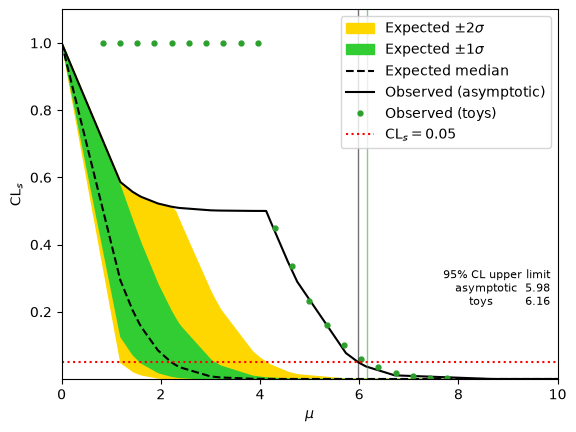

In [8]:
mu_asy = np.array([test.poi_test for test in asy_limit.results])
obs_asy = np.array([test.cls for test in asy_limit.results])
exp_asy = np.array([test.expected_cls for test in asy_limit.results])

mu_toy = np.array([test.poi_test for test in toy_limit.results])
obs_toy = np.array([test.cls for test in toy_limit.results])

fig, ax = plt.subplots()

ax.fill_between(mu_asy, exp_asy[:, 0], exp_asy[:, 4],
                color='gold', label=r'Expected $\pm2\sigma$')
ax.fill_between(mu_asy, exp_asy[:, 1], exp_asy[:, 3],
                color='limegreen', label=r'Expected $\pm1\sigma$')
ax.plot(mu_asy, exp_asy[:, 2], 'k--', label='Expected median')
ax.plot(mu_asy, obs_asy, color='black', label='Observed (asymptotic)')
ax.plot(mu_toy, obs_toy, 'o', color='C2', markersize=3.5,
        label='Observed (toys)')
ax.axhline(0.05, color='red', ls=':', label=r'$\mathrm{CL}_s = 0.05$')

ax.axvline(asy_limit.observed, color='black', ls='-', lw=1.0, alpha=0.55)
ax.axvline(toy_limit.observed, color='C2', ls='-', lw=1.0, alpha=0.55)

# ax.set_yscale('log')
ax.set_xlim(0, 10)
ax.set_ylim(1e-4, 1.1)
ax.set_xlabel(r'$\mu$')
ax.set_ylabel(r'$\mathrm{CL}_s$')
ax.legend(loc='upper right')
ax.text(0.985, 0.30,
        '95% CL upper limit\n'
        f'asymptotic  {asy_limit.observed:.2f}\n'
        f'toys        {toy_limit.observed:.2f}',
        transform=ax.transAxes, ha='right', va='top', fontsize=8)